# 15 - Forced vibrations and resonance

**MATH 331 - Differential Equations.** Lecture plan: Session 15 (Units 6 and 15: forced vibrations, beats, resonance, RLC circuits).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 2.6, Forced oscillations and resonance**: Example 2.6.1
  and Figure 2.6.2 (beats), pure resonance and Figure 2.6.3, the damped case with Figures 2.6.4
  and 2.6.5 (practical resonance). Exercises 2.6.2, 2.6.3, 2.6.4, 2.6.5, 2.6.6, 2.6.8 (numbers of
  the list at the end of the chapter).
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012): **Section
  3.6, Spring Systems**, the part on undamped forced motion (formula (18); beats), and **Section 3.7, RCL Circuits**
  (Table 3.4, Example 2). Their formulas are rewritten here with the letters of Lebl.
* Related notebooks: 14 (particular solutions, the factor $x$, transient and steady part), 07
  ($\omega_0$, $p$, kinds of damping), 13 (first-order circuits).

**What you will learn**
1. What a periodic force does to a spring without damping: beats.
2. Pure resonance, and why it is the limit of beats.
3. With damping: the steady oscillation that remains, its amplitude and its delay.
4. How to draw and read an **amplitude-response curve**, for a spring and for a circuit.

## 1. Theory in brief

A mass on a spring with a damper (notebook 07), pushed by a periodic force:

$$ \boxed{\;m\,x'' + c\,x' + k\,x = F_0\cos\omega t\;} \qquad \omega_0 = \sqrt{\tfrac km}, \quad p = \tfrac{c}{2m} . $$

$\omega_0$ is the **natural** frequency (the one of the free motion); $\omega$ is the frequency
of the **force**. A particular solution, by the guesses of notebook 14:

| Case | Particular solution |
|---|---|
| no damping, $\omega \ne \omega_0$ | $\dfrac{F_0}{m\,(\omega_0^2 - \omega^2)}\cos\omega t$ |
| no damping, $\omega = \omega_0$ (**pure resonance**) | $\dfrac{F_0}{2m\,\omega_0}\;t\,\sin\omega_0 t$ |
| damping $c > 0$ | $A\cos\omega t + B\sin\omega t = C\cos(\omega t - \gamma)$, $\quad C = \dfrac{F_0}{m\sqrt{(2\omega p)^2 + (\omega_0^2 - \omega^2)^2}}$ |

With damping the solution of the homogeneous equation dies out (the **transient**) and the
particular solution above is what remains: the **steady periodic solution**. Its amplitude $C$
depends on $\omega$; it is largest at $\omega = \sqrt{\omega_0^2 - 2p^2}$ (**practical
resonance**), if this number exists.

"Do not memorize the above formula, you should instead remember the ideas involved" (Lebl).

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: cosine_forced_response, steady_state, practical_resonance, forced_response, check, check_solution).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. A force on a spring without damping

*Lebl, Example 2.6.1.* $\;0.5\,x'' + 8x = 10\cos\pi t$, $\;x(0) = 0$, $x'(0) = 0$. By hand:

1. $\omega_0 = \sqrt{8/0.5} = 4$, and the force has $\omega = \pi$: not the same.
2. Guess $x_p = A\cos\pi t$. (No sine is needed: the equation has no $x'$, so a cosine stays a
   cosine.) $\;-0.5\,\pi^2A + 8A = 10$, so $A = \dfrac{20}{16 - \pi^2} \approx 3.262$.
3. $x = C_1\cos 4t + C_2\sin 4t + A\cos\pi t$. Initial conditions **on the sum** (notebook 14):
   $C_1 + A = 0$ and $4C_2 = 0$.

$$ x = \frac{20}{16 - \pi^2}\,(\cos\pi t - \cos 4t) . $$

Two cosines of the same size and different frequencies: the result does not look like a cosine.

In [2]:
t = sp.symbols("t")
A, B = sp.symbols("A B")

MASS, STIFFNESS, FORCE = 0.5, 8.0, 10.0     # Lebl, Example 2.6.1 (forcing frequency: pi)
omega_0 = np.sqrt(STIFFNESS / MASS)

guess = A * sp.cos(sp.pi * t)
equation = sp.Rational(1, 2) * sp.diff(guess, t, 2) + 8 * guess - 10 * sp.cos(sp.pi * t)
size = sp.solve(sp.simplify(equation / sp.cos(sp.pi * t)), A)[0]
lebl = size * (sp.cos(sp.pi * t) - sp.cos(4 * t))
print("omega_0 =", omega_0, "  A =", size, "=", round(float(size), 3))

check_times = np.linspace(0.0, 20.0, 201)
assert np.isclose(float(size), 20 / (16 - np.pi ** 2))
assert np.allclose(sp.lambdify(t, lebl)(check_times),
                   ol.cosine_forced_response(check_times, MASS, 0.0, STIFFNESS, FORCE, np.pi))     # the library agrees

omega_0 = 4.0   A = 20/(16 - pi**2) = 3.262


## 3. Beats

The identity $\;\cos v - \cos u = 2\sin\dfrac{u - v}{2}\,\sin\dfrac{u + v}{2}\;$ turns the sum into a
**product**:

$$ x = \underbrace{\frac{40}{16 - \pi^2}\,\sin\frac{(4 - \pi)\,t}{2}}_{\text{slow: the envelope}}\;
       \underbrace{\sin\frac{(4 + \pi)\,t}{2}}_{\text{fast}} . $$

A fast oscillation whose size goes slowly up and down. When the two frequencies are close this
is what the ear hears as **beats**: a piano tuner listens to them, and they disappear when the
string and the tuning fork agree; an unbalanced washing machine shakes, calms down and shakes
again (both examples from Adkins and Davidson, Section 3.6).

Before running: the envelope is zero when $\sin\frac{(4 - \pi)t}{2} = 0$. How long does one beat
last?

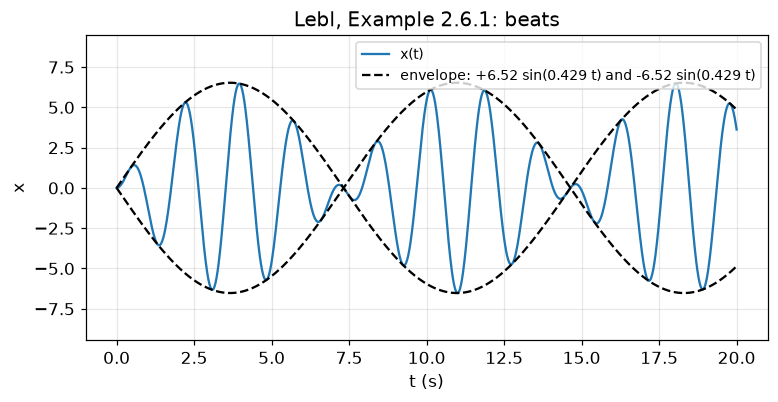

largest size 6.52; one beat lasts pi / 0.429 = 7.32 s; the fast oscillation has period 1.76 s


In [3]:
FIGURE_SIZE = (8.0, 3.6)
N_POINTS = 1200
BEATS_END = 20.0
HEADROOM = 1.45

slow, fast = (omega_0 - np.pi) / 2, (omega_0 + np.pi) / 2
times = np.linspace(0.0, BEATS_END, N_POINTS)
motion = ol.cosine_forced_response(times, MASS, 0.0, STIFFNESS, FORCE, np.pi)
envelope = 2 * float(size) * np.sin(slow * times)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(times, motion, "-", linewidth=1.5, label="x(t)")
ax.plot(times, envelope, "--", color="black", label=f"envelope: +{2 * float(size):.2f} sin({slow:.3f} t) and -{2 * float(size):.2f} sin({slow:.3f} t)")
ax.plot(times, -envelope, "--", color="black")
ax.set_xlabel("t (s)")
ax.set_ylabel("x")
ax.set_title("Lebl, Example 2.6.1: beats")
ax.set_ylim(-HEADROOM * 2 * float(size), HEADROOM * 2 * float(size))            # room for the legend
ax.legend(loc="upper right")
plt.show()

assert np.allclose(motion, envelope * np.sin(fast * times))                    # the product form
print(f"largest size {2 * float(size):.2f}; one beat lasts pi / {slow:.3f} = {np.pi / slow:.2f} s; "
      f"the fast oscillation has period {2 * np.pi / fast:.2f} s")

*The plot shows* 20 seconds of the motion (solid): a fast oscillation, with period 1.76 s, whose
size swells to 6.52 and shrinks to zero again and again. The two dashed curves are the envelope
$\pm 6.52\sin(0.429\,t)$: the motion stays between them and is zero with them at $t = 7.32$ and
$t = 14.64$. (Answer: one beat lasts $\pi/0.429 = 2\pi/(4 - \pi) \approx 7.32$ s.)

## 4. Pure resonance

Now let the force have exactly the natural frequency: $\omega = \omega_0$. The guess
$A\cos\omega_0t$ solves the homogeneous equation, so (notebook 14, Section 4) it must be
multiplied by $t$, and this time the sine is needed: $x_p = t\,(A\cos\omega_0t + B\sin\omega_0t)$.
Substituting gives $A = 0$, $B = \dfrac{F_0}{2m\omega_0}$:

$$ x_p = \frac{F_0}{2m\,\omega_0}\;t\,\sin\omega_0t . $$

The oscillation **grows without bound**: each push arrives at the right moment, like the pushes
on a swing. *Lebl's Figure 2.6.3* is the case $F_0 = 2$, $m = 1$, $\omega_0 = \pi$:
$\;x = \tfrac1\pi\,t\sin\pi t$.

**Resonance is the limit of beats.** As in notebook 14, the solution from rest for
$\omega \ne \omega_0$ tends to the resonant one:

$$ \frac{F_0}{m}\,\frac{\cos\omega t - \cos\omega_0t}{\omega_0^2 - \omega^2}
   \;\longrightarrow\; \frac{F_0}{2m\,\omega_0}\;t\,\sin\omega_0t \qquad (\omega \to \omega_0) . $$

As $\omega$ approaches $\omega_0$ the beats get longer and larger; at $\omega_0$ the first beat
never ends.

(Real structures have damping and stop being linear long before "without bound". And the
collapse of the Tacoma Narrows bridge, often shown as an example of resonance, was a different
phenomenon: see Lebl, Section 2.6.1, and the paper cited in his footnote.)

Before moving the slider (the spring of Section 2, $\omega_0 = 4$): at $\omega = 3.5$, how long is
one beat? At $\omega = 4$, how fast does the size grow?

limit: t*sin(omega_0*t)/(2*omega_0)


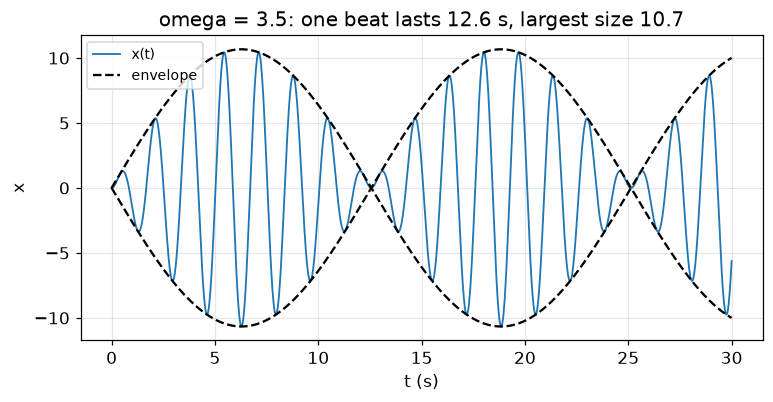

In [4]:
w, w_0 = sp.symbols("omega omega_0", positive=True)
limit = sp.limit((sp.cos(w * t) - sp.cos(w_0 * t)) / (w_0 ** 2 - w ** 2), w, w_0)
print("limit:", limit)
assert sp.simplify(limit - t * sp.sin(w_0 * t) / (2 * w_0)) == 0
assert np.allclose(ol.cosine_forced_response(check_times, 1.0, 0.0, np.pi ** 2, 2.0, np.pi),
                   check_times * np.sin(np.pi * check_times) / np.pi)             # Lebl, Figure 2.6.3

SLIDER_END = 30.0
DEFAULT_OMEGA = 3.5
OMEGA_RANGE = (2.5, 5.0, 0.05)              # minimum, maximum, step


def plot_beats(omega=DEFAULT_OMEGA):
    # the motion from rest of the spring of Section 2 under the force 10 cos(omega t), with its envelope
    times = np.linspace(0.0, SLIDER_END, N_POINTS)
    slow, fast = (omega_0 - omega) / 2, (omega_0 + omega) / 2
    envelope = FORCE / MASS * np.abs(times * np.sinc(slow * times / np.pi)) / (2 * fast)   # |sin(slow t) / slow| / (2 fast)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(times, ol.cosine_forced_response(times, MASS, 0.0, STIFFNESS, FORCE, omega), "-", linewidth=1.2, label="x(t)")
    ax.plot(times, envelope, "--", color="black", label="envelope")
    ax.plot(times, -envelope, "--", color="black")
    ax.set_xlabel("t (s)")
    ax.set_ylabel("x")
    if np.isclose(omega, omega_0):
        ax.set_title(f"omega = {omega:g} = omega_0: pure resonance, the size grows by {FORCE / (2 * MASS * omega_0):g} per second")
    else:
        ax.set_title(f"omega = {omega:g}: one beat lasts {np.pi / abs(slow):.1f} s, largest size "
                     f"{2 * FORCE / (MASS * abs(omega_0 ** 2 - omega ** 2)):.1f}")
    ax.legend(loc="upper left")
    plt.show()


plot_beats()

In [5]:
interact(plot_beats,
         omega=FloatSlider(value=DEFAULT_OMEGA, min=OMEGA_RANGE[0], max=OMEGA_RANGE[1], step=OMEGA_RANGE[2],
                           description="omega", continuous_update=False));

interactive(children=(FloatSlider(value=3.5, continuous_update=False, description='omega', max=5.0, min=2.5, s...

*The static plot shows*, for $\omega = 3.5$: 30 seconds of beats. The size rises to 10.7 and
returns to zero at $t = 12.6$ and $t = 25.1$; the dashed envelope touches the peaks.

(Answers: $2\pi/(4 - 3.5) \approx 12.6$ s. At $\omega = 4$ the envelope is the straight line
$\dfrac{F_0}{2m\omega_0}\,t = 2.5\,t$: the size reaches 75 after 30 s.)

## 5. With damping: what stays

With a damper, $c > 0$, the guess of notebook 14 always works, and now it needs the sine:
$x_p = A\cos\omega t + B\sin\omega t$. Substituting and collecting cosines and sines:

$$ (k - m\omega^2)\,A + c\,\omega\,B = F_0, \qquad -c\,\omega\,A + (k - m\omega^2)\,B = 0 . $$

Written as one cosine (notebook 07), $x_p = C\cos(\omega t - \gamma)$ with

$$ C = \sqrt{A^2 + B^2} = \frac{F_0}{\sqrt{(k - m\omega^2)^2 + (c\,\omega)^2}} , \qquad
   \gamma = \text{the angle of the point } (A, B) . $$

(Divide by $m$ inside the root to get the form of Section 1. This $C$ is Lebl's letter for the
amplitude; in notebook 07 it was $A$, which here is a coefficient of the guess.) Since $B > 0$
(for $F_0 > 0$), $\gamma$ is between 0 and $\pi$: **the response is late** with respect to the force.

The general solution is $x = x_{tr} + x_{sp}$ (Lebl's names): the **transient** $x_{tr}$, the
solution of the homogeneous equation, contains the initial data and dies out (like $e^{-pt}$ when the damping is below critical, as
here); the
**steady periodic** $x_{sp} = x_p$ contains none.

*Lebl's Figure 2.6.4*: $k = 1$, $m = 1$, $F_0 = 1$, $c = 0.7$, $\omega = 1.1$, several initial
conditions. Before running: after which time is the transient below 1 % of its first size?

A = -0.330, B = 1.209;  C = 1.253, gamma = 1.837 rad


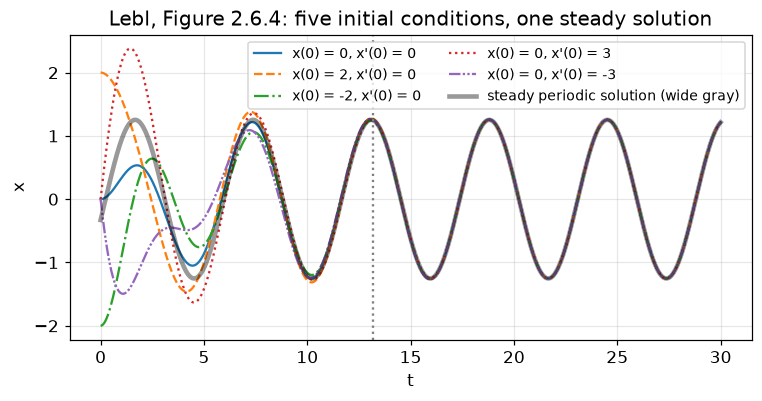

p = 0.35: exp(-p t) is below 1 % after t = 13.2;  the response is late by gamma / omega = 1.67


In [6]:
FIGURE_4 = {"m": 1.0, "c": 0.7, "k": 1.0, "F0": 1.0, "omega": 1.1}        # Lebl, Figure 2.6.4
STARTS = ((0.0, 0.0), (2.0, 0.0), (-2.0, 0.0), (0.0, 3.0), (0.0, -3.0))     # pairs x(0), x'(0)
STYLES = ("-", "--", "-.", ":", (0, (5, 1, 1, 1, 1, 1)))
TRANSIENT_END = 30.0
ONE_PERCENT = 0.01

exact = {name: sp.Rational(str(value)) for name, value in FIGURE_4.items()}
guess = A * sp.cos(exact["omega"] * t) + B * sp.sin(exact["omega"] * t)
residual = sp.expand(exact["m"] * sp.diff(guess, t, 2) + exact["c"] * sp.diff(guess, t) + exact["k"] * guess
                     - exact["F0"] * sp.cos(exact["omega"] * t))
found = sp.solve([residual.coeff(sp.cos(exact["omega"] * t)), residual.coeff(sp.sin(exact["omega"] * t))], [A, B])
steady_size, steady_phase = ol.steady_state(**FIGURE_4)
print(f"A = {float(found[A]):.3f}, B = {float(found[B]):.3f};  C = {steady_size:.3f}, gamma = {steady_phase:.3f} rad")
assert np.isclose(steady_size, float(sp.sqrt(found[A] ** 2 + found[B] ** 2)))
assert np.isclose(steady_phase, float(sp.atan2(found[B], found[A])))

p_value = FIGURE_4["c"] / (2 * FIGURE_4["m"])
settled = np.log(1 / ONE_PERCENT) / p_value
times = np.linspace(0.0, TRANSIENT_END, N_POINTS)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
for (x0, v0), style in zip(STARTS, STYLES):
    ax.plot(times, ol.cosine_forced_response(times, x0=x0, v0=v0, **FIGURE_4), linestyle=style, linewidth=1.5,
            label=f"x(0) = {x0:g}, x'(0) = {v0:g}")
ax.plot(times, steady_size * np.cos(FIGURE_4["omega"] * times - steady_phase), "-", color="black", linewidth=3, alpha=0.4,
        label="steady periodic solution (wide gray)")
ax.axvline(settled, linestyle=":", color="gray")
ax.set_xlabel("t")
ax.set_ylabel("x")
ax.set_title("Lebl, Figure 2.6.4: five initial conditions, one steady solution")
ax.legend(loc="upper right", ncol=2)
plt.show()
print(f"p = {p_value:g}: exp(-p t) is below 1 % after t = {settled:.1f};  the response is late by gamma / omega = {steady_phase / FIGURE_4['omega']:.2f}")

*The plot shows* five solutions with different initial conditions (different line styles). They
start between $-2$ and $2$ and from about the dotted vertical line at $t = 13.2$ they cannot be
told from the wide gray curve, the steady periodic solution: a cosine of amplitude 1.25 with the
period of the force, 5.71. (Answer: $\ln 100 / p = \ln 100/0.35 \approx 13.2$.)

## 6. The amplitude-response curve

Keep the spring, the damper and the size $F_0$ of the force; change only the frequency $\omega$.
The amplitude $C(\omega)$ of the steady solution, drawn against $\omega$, is the
**amplitude-response curve**. Three things to read on it (the last two are in Lebl, Section 2.6.2):

* $C(0) = F_0/k$: a very slow force just stretches the spring;
* $C \to 0$ for large $\omega$: wiggling very fast on a swing does not move it;
* in between there may be a **maximum**, at $\;\omega_r = \sqrt{\omega_0^2 - 2p^2}\;$ (set the
  derivative of $(k - m\omega^2)^2 + (c\omega)^2$ to zero). This is **practical resonance**. It is
  **below** $\omega_0$ (only a little when the damping is small), and it exists only if $\omega_0^2 > 2p^2$, that is $c^2 < 2mk$.

*Lebl's Figure 2.6.5*: $k = m = F_0 = 1$ with $c = 0.4$, $0.8$ and $1.6$.

c = 0.4: practical resonance at omega = 0.959, amplitude 2.55
c = 0.8: practical resonance at omega = 0.825, amplitude 1.36
c = 1.6: no practical resonance (c^2 = 2.56 is not below 2 m k = 2)


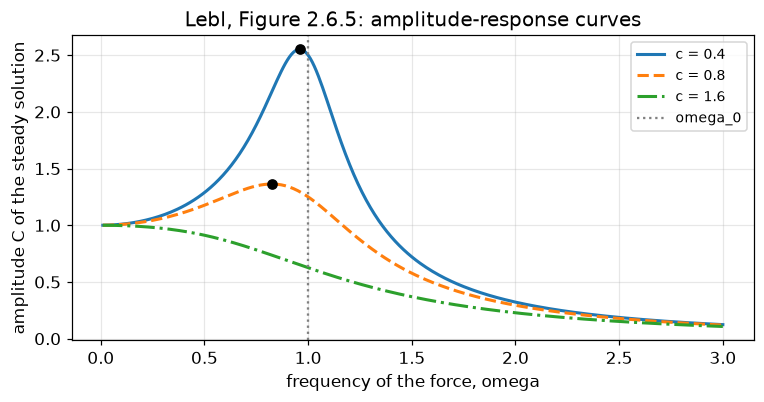

In [7]:
UNIT = {"m": 1.0, "k": 1.0, "F0": 1.0}      # Lebl, Figure 2.6.5
DAMPINGS = (0.4, 0.8, 1.6)
CURVE_STYLES = ("-", "--", "-.")
OMEGA_MAX = 3.0
N_CURVE = 300


def response_curve(frequencies, c):
    # the amplitude of the steady solution at each frequency
    return np.array([ol.steady_state(UNIT["m"], c, UNIT["k"], UNIT["F0"], value)[0] for value in frequencies])


frequencies = np.linspace(OMEGA_MAX / N_CURVE, OMEGA_MAX, N_CURVE)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
for damping, style in zip(DAMPINGS, CURVE_STYLES):
    ax.plot(frequencies, response_curve(frequencies, damping), linestyle=style, linewidth=2, label=f"c = {damping:g}")
    best = ol.practical_resonance(UNIT["m"], damping, UNIT["k"])
    if best > 0:
        height = ol.steady_state(UNIT["m"], damping, UNIT["k"], UNIT["F0"], best)[0]
        ax.plot(best, height, "o", color="black", markersize=6)
        print(f"c = {damping:g}: practical resonance at omega = {best:.3f}, amplitude {height:.2f}")
    else:
        print(f"c = {damping:g}: no practical resonance (c^2 = {damping ** 2:g} is not below 2 m k = {2 * UNIT['m'] * UNIT['k']:g})")
ax.axvline(np.sqrt(UNIT["k"] / UNIT["m"]), linestyle=":", color="gray", label="omega_0")
ax.set_xlabel("frequency of the force, omega")
ax.set_ylabel("amplitude C of the steady solution")
ax.set_title("Lebl, Figure 2.6.5: amplitude-response curves")
ax.legend(loc="upper right")
plt.show()

*The plot shows* three amplitude-response curves, all starting at $C = 1$ for slow forces and
falling to about 0.1 at $\omega = 3$. With $c = 0.4$ (solid) there is a tall peak, 2.55, at
$\omega = 0.959$ (black dot), just left of the dotted line $\omega_0 = 1$. With $c = 0.8$
(dashed) the peak is lower and further left: 1.36 at $\omega = 0.825$. With $c = 1.6$ (dash-dot)
there is no peak: the curve only falls.

**Sliders.** Before moving them: for $m = k = 1$, above which value of $c$ does the peak
disappear? And at $\omega = \omega_0$, what is the amplitude when $c = 0.1$?

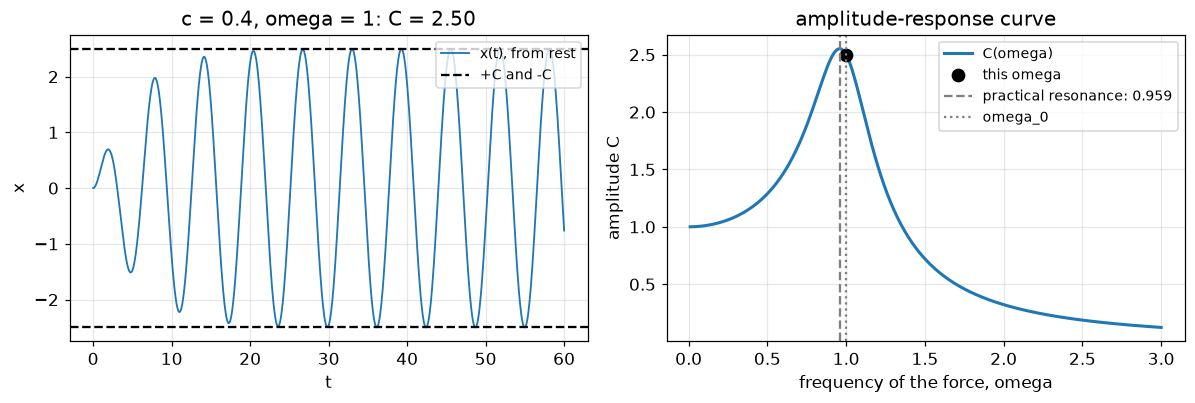

In [8]:
RESPONSE_DEFAULTS = {"c": 0.4, "omega": 1.0}
C_RANGE = (0.1, 2.0, 0.1)                   # minimum, maximum, step (no slider value gives pure resonance)
FORCE_RANGE = (0.1, OMEGA_MAX, 0.05)
MOTION_END = 60.0
WIDE_FIGURE = (11.0, 3.8)


def plot_response(c=RESPONSE_DEFAULTS["c"], omega=RESPONSE_DEFAULTS["omega"]):
    # left: the motion from rest, with the lines at +C and -C; right: the response curve with this omega marked
    height = ol.steady_state(UNIT["m"], c, UNIT["k"], UNIT["F0"], omega)[0]
    best = ol.practical_resonance(UNIT["m"], c, UNIT["k"])
    times = np.linspace(0.0, MOTION_END, N_POINTS)
    fig, (left, right) = plt.subplots(1, 2, figsize=WIDE_FIGURE)
    left.plot(times, ol.cosine_forced_response(times, UNIT["m"], c, UNIT["k"], UNIT["F0"], omega), "-", linewidth=1.2,
              label="x(t), from rest")
    left.axhline(height, linestyle="--", color="black", label="+C and -C")
    left.axhline(-height, linestyle="--", color="black")
    left.set_xlabel("t")
    left.set_ylabel("x")
    left.set_title(f"c = {c:g}, omega = {omega:g}: C = {height:.2f}")
    left.legend(loc="upper right")

    right.plot(frequencies, response_curve(frequencies, c), "-", linewidth=2, label="C(omega)")
    right.plot(omega, height, "o", color="black", markersize=8, label="this omega")
    if best > 0:
        right.axvline(best, linestyle="--", color="gray", label=f"practical resonance: {best:.3f}")
    right.axvline(np.sqrt(UNIT["k"] / UNIT["m"]), linestyle=":", color="gray", label="omega_0")
    right.set_xlabel("frequency of the force, omega")
    right.set_ylabel("amplitude C")
    right.set_title("no practical resonance" if best == 0 else "amplitude-response curve")
    right.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


plot_response()

In [9]:
interact(plot_response,
         c=FloatSlider(value=RESPONSE_DEFAULTS["c"], min=C_RANGE[0], max=C_RANGE[1], step=C_RANGE[2], description="c",
                       continuous_update=False),
         omega=FloatSlider(value=RESPONSE_DEFAULTS["omega"], min=FORCE_RANGE[0], max=FORCE_RANGE[1], step=FORCE_RANGE[2],
                           description="omega", continuous_update=False));

interactive(children=(FloatSlider(value=0.4, continuous_update=False, description='c', max=2.0, min=0.1), Floa...

*The static plot shows*, for $c = 0.4$ and $\omega = 1$. Left: the motion from rest grows during
the first 20 time units and then oscillates between the dashed lines at $\pm 2.5$. Right: the
response curve with a black dot at $\omega = 1$, height 2.5, just right of the dashed line of
practical resonance (0.959) and on the dotted line $\omega_0$.

(Answers: the peak disappears when $c^2 \ge 2mk$, that is $c \ge \sqrt2 \approx 1.41$. At
$\omega = \omega_0$ the amplitude is $F_0/(c\,\omega_0)$: 10 for $c = 0.1$, ten times what the same
force does when applied slowly.)

## 7. The same curve in a circuit

A coil $L$, a resistor $R$ and a capacitor of capacitance $C$ in series with a voltage source
$E(t)$. The voltage across the coil is $L\,I' = L\,q''$, across the resistor $R\,I = R\,q'$, across
the capacitor $q/C$ (notebook 13), where $q$ is the charge on the capacitor and $I = q'$ the
current; Kirchhoff's law says that their sum is $E(t)$. Put this next to Newton's law, term by
term:

| Spring: inertia + damper + spring = applied force | Circuit: coil + resistor + capacitor = applied voltage |
|---|---|
| inertia $m\,x''$ | coil $L\,q''$ |
| damper $c\,x'$ | resistor $R\,q'$ |
| spring $k\,x$ | capacitor $q/C$ |
| applied force $F(t)$ | applied voltage $E(t)$ |
| $m\,x'' + c\,x' + k\,x = F(t)$ | $L\,q'' + R\,q' + \dfrac1C\,q = E(t)$ |

(Adkins and Davidson, Section 3.7, Table 3.4). So $\omega_0 = \dfrac{1}{\sqrt{LC}}$ and $p = \dfrac{R}{2L}$, and **every result
of this notebook holds with the new letters**.

*A constant voltage* (Adkins and Davidson, Section 3.7, Example 2). $L = 1$ H, $R = 9$ ohm,
$C = \tfrac1{14}$ F, a battery of 14 V, no charge and no current at the start:
$\;q'' + 9q' + 14q = 14$. The steady part is the constant $q_p = 1$ (notebook 14: a constant
guess); the roots are $-2$ and $-7$, and the initial conditions give

$$ q = 1 + \tfrac25e^{-7t} - \tfrac75e^{-2t} . $$

*An alternating voltage* $E_0\cos\omega t$ gives the response curve of Section 6 for the charge.
The **current** $I = q'$ has amplitude $\omega$ times that of the charge, and this is largest
**exactly** at $\omega_0$, whatever $R$ is. Tuning a radio is choosing the capacitor so that
$1/\sqrt{LC}$ is the frequency of the station.

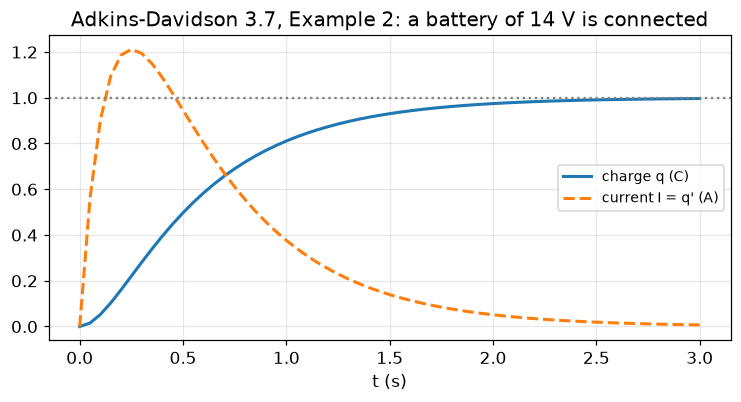

largest current 1.21 A at t = 0.25 s
omega_0 = 1 / sqrt(L C) = 3.742 rad/s


In [10]:
INDUCTANCE, RESISTANCE, CAPACITANCE, VOLTAGE = 1.0, 9.0, 1 / 14, 14.0      # Adkins-Davidson 3.7, Example 2
CIRCUIT_END = 3.0
N_CIRCUIT = 61
RESISTANCES = (1.0, 3.0, 9.0)               # for the check on the current
N_FINE = 3001

charge = 1 + sp.Rational(2, 5) * sp.exp(-7 * t) - sp.Rational(7, 5) * sp.exp(-2 * t)
current = sp.diff(charge, t)
assert sp.simplify(sp.diff(charge, t, 2) + 9 * current + 14 * charge - 14) == 0
assert charge.subs(t, 0) == 0 and current.subs(t, 0) == 0

times = np.linspace(0.0, CIRCUIT_END, N_CIRCUIT)
numerical = ol.forced_response(times, INDUCTANCE, RESISTANCE, 1 / CAPACITANCE, lambda s: VOLTAGE)
assert np.allclose(numerical, sp.lambdify(t, charge)(times))                 # variation of parameters agrees

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(times, sp.lambdify(t, charge)(times), "-", linewidth=2, label="charge q (C)")
ax.plot(times, sp.lambdify(t, current)(times), "--", linewidth=2, label="current I = q' (A)")
ax.axhline(1.0, linestyle=":", color="gray")
ax.set_xlabel("t (s)")
ax.set_title("Adkins-Davidson 3.7, Example 2: a battery of 14 V is connected")
ax.legend(loc="center right")
plt.show()

peak_time = np.log(7 / 2) / 5                                               # I' = 0 where 2 exp(-2t) = 7 exp(-7t)
assert abs(float(sp.diff(current, t).subs(t, peak_time))) < 1e-12
print(f"largest current {float(current.subs(t, peak_time)):.2f} A at t = {peak_time:.2f} s")

# the current of an alternating voltage is largest exactly at omega_0, for any resistance
natural = 1 / np.sqrt(INDUCTANCE * CAPACITANCE)
fine = np.linspace(natural / 2, 2 * natural, N_FINE)
for resistance in RESISTANCES:
    amplitudes = np.array([value * ol.steady_state(INDUCTANCE, resistance, 1 / CAPACITANCE, 1.0, value)[0] for value in fine])
    assert np.isclose(fine[np.argmax(amplitudes)], natural, atol=fine[1] - fine[0])
print(f"omega_0 = 1 / sqrt(L C) = {natural:.3f} rad/s")

*The plot shows* the first 3 seconds after the battery is connected. The charge (solid) rises
from 0 towards the dotted line at 1 C without ever crossing it (the circuit is overdamped, two
real roots, and starts from rest). The current (dashed) rises quickly to its largest value, 1.21 A, at $t = 0.25$ s and then
dies out: in the long term the capacitor is charged and nothing flows.

## 8. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

*Lebl, Exercise 2.6.8.* $m = 5$, $k = 20$, $F_0 = 5$, no damping; the force is $F_0\cos\omega t$.

* Which $\omega$ gives pure resonance?
* At that $\omega$, by how much does the size of the oscillation grow each second?
* What is the size at $t = 100$?

And two statements, `True` or `False`:

* with damping, the frequency of practical resonance is below $\omega_0$;
* with more damping, the peak of the amplitude-response curve is higher.

In [11]:
my_omega = None
my_growth_per_second = None
my_size_at_100 = None
my_below_omega_0 = None         # True or False
my_higher_peak = None           # True or False
# ---- your answers go above this line; the lines below check them (nothing to change) ----

EIGHT = {"m": 5.0, "k": 20.0, "F0": 5.0}    # Lebl, Exercise 2.6.8
resonant = np.sqrt(EIGHT["k"] / EIGHT["m"])
growth = EIGHT["F0"] / (2 * EIGHT["m"] * resonant)
ol.check("Exercise 1, omega", my_omega, resonant)
ol.check("Exercise 1, growth", my_growth_per_second, growth)
ol.check("Exercise 1, size at t = 100", my_size_at_100, growth * 100)
ol.check("Exercise 1, below omega_0", my_below_omega_0, True)
ol.check("Exercise 1, higher peak", my_higher_peak, False);

Exercise 1, omega: no answer yet (replace None with your value)
Exercise 1, growth: no answer yet (replace None with your value)
Exercise 1, size at t = 100: no answer yet (replace None with your value)
Exercise 1, below omega_0: no answer yet (replace None with your value)
Exercise 1, higher peak: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Lebl, Exercise 2.6.6.* $m = 4$, $k = 4$, $c = 1$, $F_0 = 2$. Find the $\omega$ of practical
resonance and the amplitude there (three decimals).

**(b)** *Lebl, Exercise 2.6.5.* A water tower in an earthquake: $m = 10\,000$ kg, and a force of
1000 N displaces it 1 m (no friction). At rest when the earthquake starts; the force is
$m\,a\,\omega^2\cos\omega t$ with $a = 1$ and 0.5 cycles per second. Find the natural frequency
(rad/s, three decimals) and the largest displacement, the constant in front of the product of
sines (m, a positive number, three decimals). The tower collapses if it moves more than 1.5 m: does it? (The book
prints no answer for this exercise; the value used by the check was computed for this notebook.)

**(c)** *Adkins and Davidson, Section 3.7, Example 2*, with other numbers: $q'' + 5q' + 6q = 12$,
$q(0) = 0$, $q'(0) = 0$. Type the charge as a SymPy formula in `t`.

In [12]:
my_resonance = None             # (a)
my_amplitude = None             # (a)
my_natural = None               # (b)
my_displacement = None          # (b)
my_collapses = None             # (b) True or False
my_charge = None                # (c)
# ---- your answers go above this line; the lines below check them (nothing to change) ----

SIX = {"m": 4.0, "c": 1.0, "k": 4.0, "F0": 2.0}                  # Lebl, Exercise 2.6.6
TOWER_MASS, TOWER_STIFFNESS, TOWER_LIMIT = 10_000.0, 1000.0, 1.5 # Lebl, Exercise 2.6.5
quake = 2 * np.pi * 0.5                                           # 0.5 cycles per second, in rad/s
tower_natural = np.sqrt(TOWER_STIFFNESS / TOWER_MASS)
tower_size = 2 * quake ** 2 / abs(tower_natural ** 2 - quake ** 2)
THREE_DECIMALS = 1e-3

best = ol.practical_resonance(SIX["m"], SIX["c"], SIX["k"])
ol.check("Exercise 2a, omega", my_resonance, best, tol=THREE_DECIMALS)
ol.check("Exercise 2a, amplitude", my_amplitude, ol.steady_state(omega=best, **SIX)[0], tol=THREE_DECIMALS)
ol.check("Exercise 2b, natural frequency", my_natural, tower_natural, tol=THREE_DECIMALS)
ol.check("Exercise 2b, displacement", my_displacement, tower_size, tol=THREE_DECIMALS)
ol.check("Exercise 2b, collapse", my_collapses, bool(tower_size > TOWER_LIMIT))
ol.check_solution("Exercise 2c", my_charge, lambda q: sp.diff(q, t, 2) + 5 * sp.diff(q, t) + 6 * q - 12, t, (0.0, 2.0),
                  conditions=((0, 0), (0, 0, 1)));              # q(0) = 0 and q'(0) = 0

Exercise 2a, omega: no answer yet (replace None with your value)
Exercise 2a, amplitude: no answer yet (replace None with your value)
Exercise 2b, natural frequency: no answer yet (replace None with your value)
Exercise 2b, displacement: no answer yet (replace None with your value)
Exercise 2b, collapse: no answer yet (replace None with your value)
Exercise 2c: no answer yet (replace None with your formula)


### Exercise 3 - Fill in

Complete the function `amplitude`: the amplitude $C$ of the steady solution of
$m\,x'' + c\,x' + k\,x = F_0\cos\omega t$. The next cell compares it with the amplitude
**measured** on the solution after the transient has died out, and then draws your own
amplitude-response curve.

In [13]:
def amplitude(omega, m, c, k, F0):
    return None                 # replace None with the formula

In [14]:
CASES = ((1.1, 1.0, 0.7, 1.0, 1.0), (0.959, 1.0, 0.4, 1.0, 1.0), (2.0, 1.0, 1.6, 1.0, 1.0),
         (0.984, 4.0, 1.0, 4.0, 2.0), (3.0, 2.0, 0.5, 8.0, 5.0))             # omega, m, c, k, F0
PERIODS_MEASURED = 3
N_MEASURED = 3001                           # points on which the largest displacement is read
FADED = 1e-9                                # the transient is this fraction of its first size
MEASURE_TOLERANCE = 1e-4

if amplitude(*CASES[0]) is None:
    print("Exercise 3: complete amplitude first")
else:
    missed = []
    for omega, m, c, k, F0 in CASES:
        late_start = np.log(1 / FADED) / (c / (2 * m))
        late = np.linspace(late_start, late_start + PERIODS_MEASURED * 2 * np.pi / omega, N_MEASURED)
        measured = np.max(np.abs(ol.cosine_forced_response(late, m, c, k, F0, omega)))
        try:
            agrees = bool(np.isclose(float(amplitude(omega, m, c, k, F0)), measured, rtol=MEASURE_TOLERANCE))
        except (TypeError, ValueError):
            agrees = None
            break
        if not agrees:
            missed.append((omega, m, c, k, F0, measured))
    if agrees is None:
        print("Exercise 3: not yet (amplitude must return one number)")
    elif missed:
        omega, m, c, k, F0, measured = missed[0]
        print(f"Exercise 3: not yet. For omega = {omega:g}, m = {m:g}, c = {c:g}, k = {k:g}, F0 = {F0:g} "
              f"the steady oscillation has amplitude {measured:.3f}; your formula gives {amplitude(omega, m, c, k, F0):.3f}")
    else:
        print(f"Exercise 3: correct on all {len(CASES)} cases")
        fig, ax = plt.subplots(figsize=FIGURE_SIZE)
        ax.plot(frequencies, [amplitude(value, SIX["m"], SIX["c"], SIX["k"], SIX["F0"]) for value in frequencies], "-", linewidth=2)
        ax.set_xlabel("frequency of the force, omega")
        ax.set_ylabel("amplitude")
        ax.set_title("Your amplitude-response curve for Exercise 2(a)")
        plt.show()

Exercise 3: complete amplitude first


### Exercise 4 - Explore

* *(Lebl, Exercises 2.6.3 and 2.6.4)* For which $c$ (with $m$, $k$ fixed) is there no practical
  resonance? For which $m$ (with $c$, $k$ fixed)? Check the first with the sliders of Section 6.
* *(Lebl, Exercise 2.6.2)* Two forces at once: $F_0\cos\omega t + F_1\cos 3\omega t$. What is the
  steady solution? (Notebook 14: one term at a time.)
* With the slider of Section 4, choose $\omega$ so that one beat lasts about 10 seconds.
* For a circuit with an inductance of 1 H and a capacitance of 0.01 F, plot the amplitude of the
  **current** ($\omega$ times the amplitude of the charge) against $\omega$ for $R = 1$, 5 and
  20 ohm. Where is the maximum? What does
  $R$ change?

In [15]:
# your code here: for example ol.steady_state(1.0, 5.0, 100.0, 1.0, 10.0) gives the amplitude and the phase
# for L = 1, R = 5, 1/C = 100, a voltage of size 1 and omega = 10

## 9. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. $\omega = \sqrt{20/5} = 2$; the size grows by $\dfrac{F_0}{2m\omega} = 0.25$ each second; 25 at
   $t = 100$. `True`; `False` (more damping: a lower peak, further left, until it disappears).
2. (a) $\omega = \sqrt{31/32} \approx 0.984$, amplitude $\dfrac{16}{3\sqrt7} \approx 2.016$.
   (b) $\omega_0 = \sqrt{0.1} \approx 0.316$ rad/s; with $\omega = \pi$ rad/s the displacement is
   $\dfrac{2a\,\omega^2}{\lvert\omega_0^2 - \omega^2\rvert} \approx 2.020$ m: the tower collapses (`True`).
   (c) $q = 2 + 4e^{-3t} - 6e^{-2t}$.
3. `return F0 / np.sqrt((k - m * omega ** 2) ** 2 + (c * omega) ** 2)`
4. No practical resonance when $c \ge \sqrt{2mk}$, or when $m \le \dfrac{c^2}{2k}$. The steady
   solution is the sum of the two steady solutions, each with its own amplitude and phase.
   $\omega = 4 \pm 0.2\pi$, that is 3.37 or 4.63 (on the slider: 3.35 or 4.65, where a beat lasts 9.7 s). The maximum of the current is at
   $\omega_0 = 10$ rad/s for every $R$; a smaller $R$ gives a taller and narrower peak.

</details>

**Where to go next:** notebook 16, equations of higher order and boundary value problems
(Session 16). A
force that is switched on and off comes back with Laplace transforms (Unit 11); a periodic force
that is not a cosine, with Fourier series.